# Visualisasi Data Penjualan POS 2024-2025
Jalankan cell dari atas ke bawah.

## Cell 1 - Import library

In [ ]:
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from google.colab import files

## Cell 2 - Upload file (klik Choose Files)

## Cell 3 - Pembersihan data

In [ ]:
n_awal = len(df)

# Rapikan spasi & huruf pada kolom teks
for kol in ["id_transaksi", "kode_gerai", "kode_kasir", "kode_produk", "status"]:
    df[kol] = df[kol].str.strip().str.upper()

# Hapus duplikat
df = df.drop_duplicates()
n_dup = n_awal - len(df)

# Standarkan tanggal (yyyy-mm-dd, dd-mm-yyyy, dd/mm/yyyy)
def parse_tanggal(t):
    t = str(t).strip()
    if t[:4].isdigit() and t[4] == "-":
        return pd.to_datetime(t, format="%Y-%m-%d", errors="coerce")
    return pd.to_datetime(t.replace("/", "-"), format="%d-%m-%Y", errors="coerce")

df["tanggal"] = df["tanggal"].apply(parse_tanggal)

# Standarkan harga ("7500,00", "13.000", "13000")
def parse_harga(h):
    h = str(h).strip()
    if "," in h:
        h = h.split(",")[0]
    h = h.replace(".", "")
    return pd.to_numeric(h, errors="coerce")

df["harga_satuan"] = df["harga_satuan"].apply(parse_harga)
df["jumlah"] = pd.to_numeric(df["jumlah"], errors="coerce")
df["diskon_persen"] = pd.to_numeric(df["diskon_persen"], errors="coerce")

# Buang data tidak valid (jumlah negatif/nol atau outlier > 12)
n_sebelum = len(df)
df = df.dropna(subset=["tanggal", "harga_satuan", "jumlah", "diskon_persen"])
df = df[(df["jumlah"] > 0) & (df["jumlah"] <= 12)]
n_invalid = n_sebelum - len(df)

# Total penjualan setelah diskon
df["total"] = df["jumlah"] * df["harga_satuan"] * (1 - df["diskon_persen"] / 100)

print(f"Duplikat dihapus          : {n_dup}")
print(f"Jumlah tidak valid dibuang: {n_invalid}")
print(f"Data bersih               : {len(df)} baris")

# Data tahun 2025
df25 = df[df["tanggal"].dt.year == 2025]

Duplikat dihapus          : 30
Jumlah tidak valid dibuang: 52
Data bersih               : 4948 baris


In [ ]:
uploaded = files.upload()
nama_file = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[nama_file]), dtype=str)
print(f"File dimuat: {nama_file} -> {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Saving CC GENERAL.csv to CC GENERAL.csv
Saving paket_a_transaksi_pos_2024_2025.csv to paket_a_transaksi_pos_2024_2025.csv
File dimuat: CC GENERAL.csv -> 5030 baris, 9 kolom


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


## Cell 4 - Bagian 1: Penjualan per bulan tahun 2025

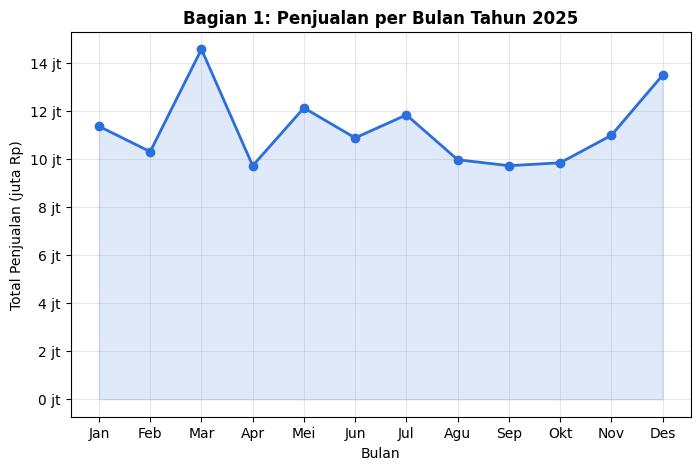

In [ ]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
              "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

jual_bulan = (df25[df25["status"] == "SELESAI"]
              .groupby(df25["tanggal"].dt.month)["total"].sum()
              .reindex(range(1, 13), fill_value=0))

rupiah = FuncFormatter(lambda x, _: f"{x/1e6:,.0f} jt")

def plot_bagian1(ax):
    ax.plot(nama_bulan, jual_bulan.values, marker="o", color="#2a6fdb", linewidth=2)
    ax.fill_between(nama_bulan, jual_bulan.values, alpha=0.15, color="#2a6fdb")
    ax.yaxis.set_major_formatter(rupiah)
    ax.set_title("Bagian 1: Penjualan per Bulan Tahun 2025", fontweight="bold")
    ax.set_xlabel("Bulan")
    ax.set_ylabel("Total Penjualan (juta Rp)")
    ax.grid(alpha=0.3)

fig, ax = plt.subplots(figsize=(8, 5))
plot_bagian1(ax)
plt.show()

## Cell 5 - Bagian 2: 10 produk terlaris tahun 2025

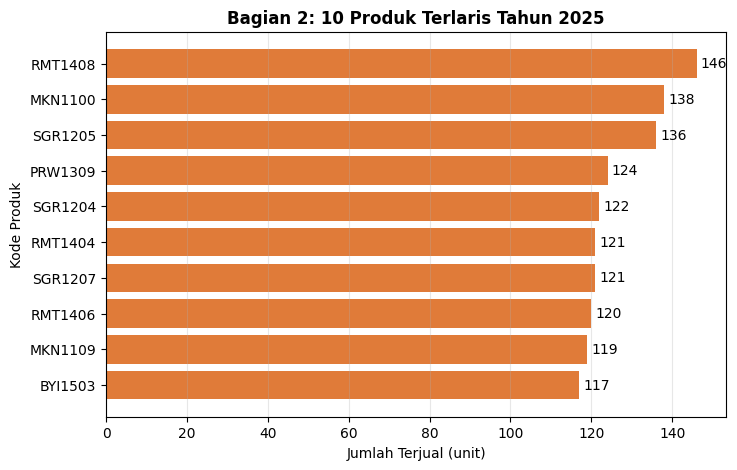

In [ ]:
top10 = (df25[df25["status"] == "SELESAI"]
         .groupby("kode_produk")["jumlah"].sum()
         .sort_values(ascending=False).head(10)
         .sort_values())

def plot_bagian2(ax):
    bars = ax.barh(top10.index, top10.values, color="#e07b39")
    ax.bar_label(bars, padding=3)
    ax.set_title("Bagian 2: 10 Produk Terlaris Tahun 2025", fontweight="bold")
    ax.set_xlabel("Jumlah Terjual (unit)")
    ax.set_ylabel("Kode Produk")
    ax.grid(axis="x", alpha=0.3)

fig, ax = plt.subplots(figsize=(8, 5))
plot_bagian2(ax)
plt.show()

## Cell 6 - Bagian 3: Proporsi transaksi berhasil vs gagal/cancel tahun 2025
Berhasil = SELESAI, Gagal/Cancel = BATAL + RETUR

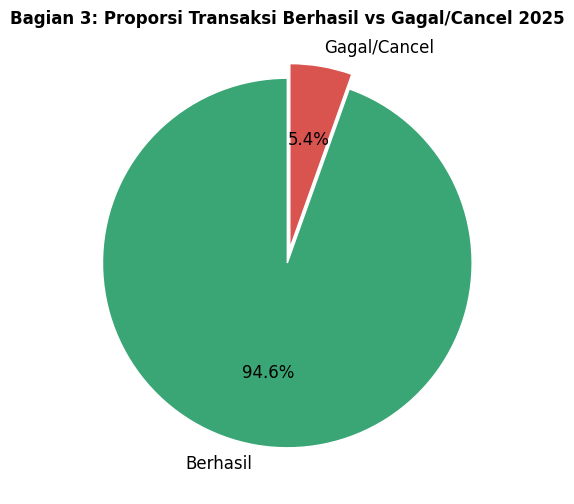

In [ ]:
status_grup = df25["status"].map(lambda s: "Berhasil" if s == "SELESAI" else "Gagal/Cancel")
prop = status_grup.value_counts().reindex(["Berhasil", "Gagal/Cancel"], fill_value=0)

def plot_bagian3(ax):
    ax.pie(prop.values, labels=prop.index, autopct="%1.1f%%", startangle=90,
           colors=["#3aa675", "#d9534f"], explode=(0, 0.08),
           wedgeprops={"edgecolor": "white"}, textprops={"fontsize": 12})
    ax.set_title("Bagian 3: Proporsi Transaksi Berhasil vs Gagal/Cancel 2025",
                 fontweight="bold")

fig, ax = plt.subplots(figsize=(6, 6))
plot_bagian3(ax)
plt.show()

## Cell 7 - Bagian 4: Hubungan jumlah beli dengan diskon

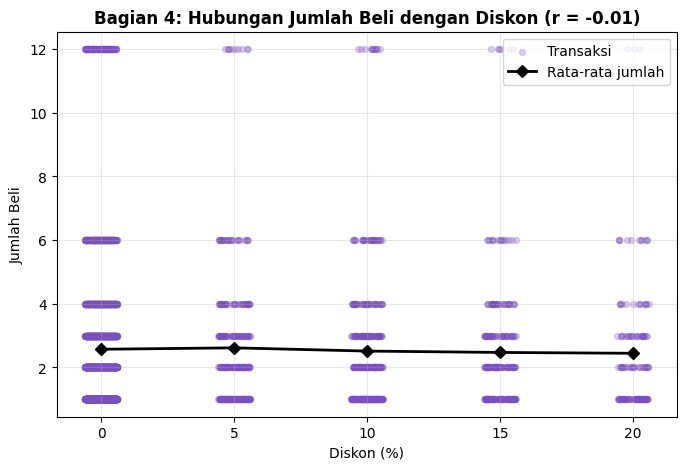

In [ ]:
korelasi = df["jumlah"].corr(df["diskon_persen"])
rata_diskon = df.groupby("diskon_persen")["jumlah"].mean()
jitter = np.random.default_rng(1).uniform(-0.6, 0.6, len(df))  # agar titik tidak menumpuk

def plot_bagian4(ax):
    ax.scatter(df["diskon_persen"] + jitter, df["jumlah"], alpha=0.25, s=18,
               color="#7b4fc4", label="Transaksi")
    ax.plot(rata_diskon.index, rata_diskon.values, color="black", marker="D",
            linewidth=2, label="Rata-rata jumlah")
    ax.set_title(f"Bagian 4: Hubungan Jumlah Beli dengan Diskon (r = {korelasi:.2f})",
                 fontweight="bold")
    ax.set_xlabel("Diskon (%)")
    ax.set_ylabel("Jumlah Beli")
    ax.set_xticks(sorted(df["diskon_persen"].unique()))
    ax.legend()
    ax.grid(alpha=0.3)

fig, ax = plt.subplots(figsize=(8, 5))
plot_bagian4(ax)
plt.show()

## Cell 8 - Gabungan 4 bagian (2x2)

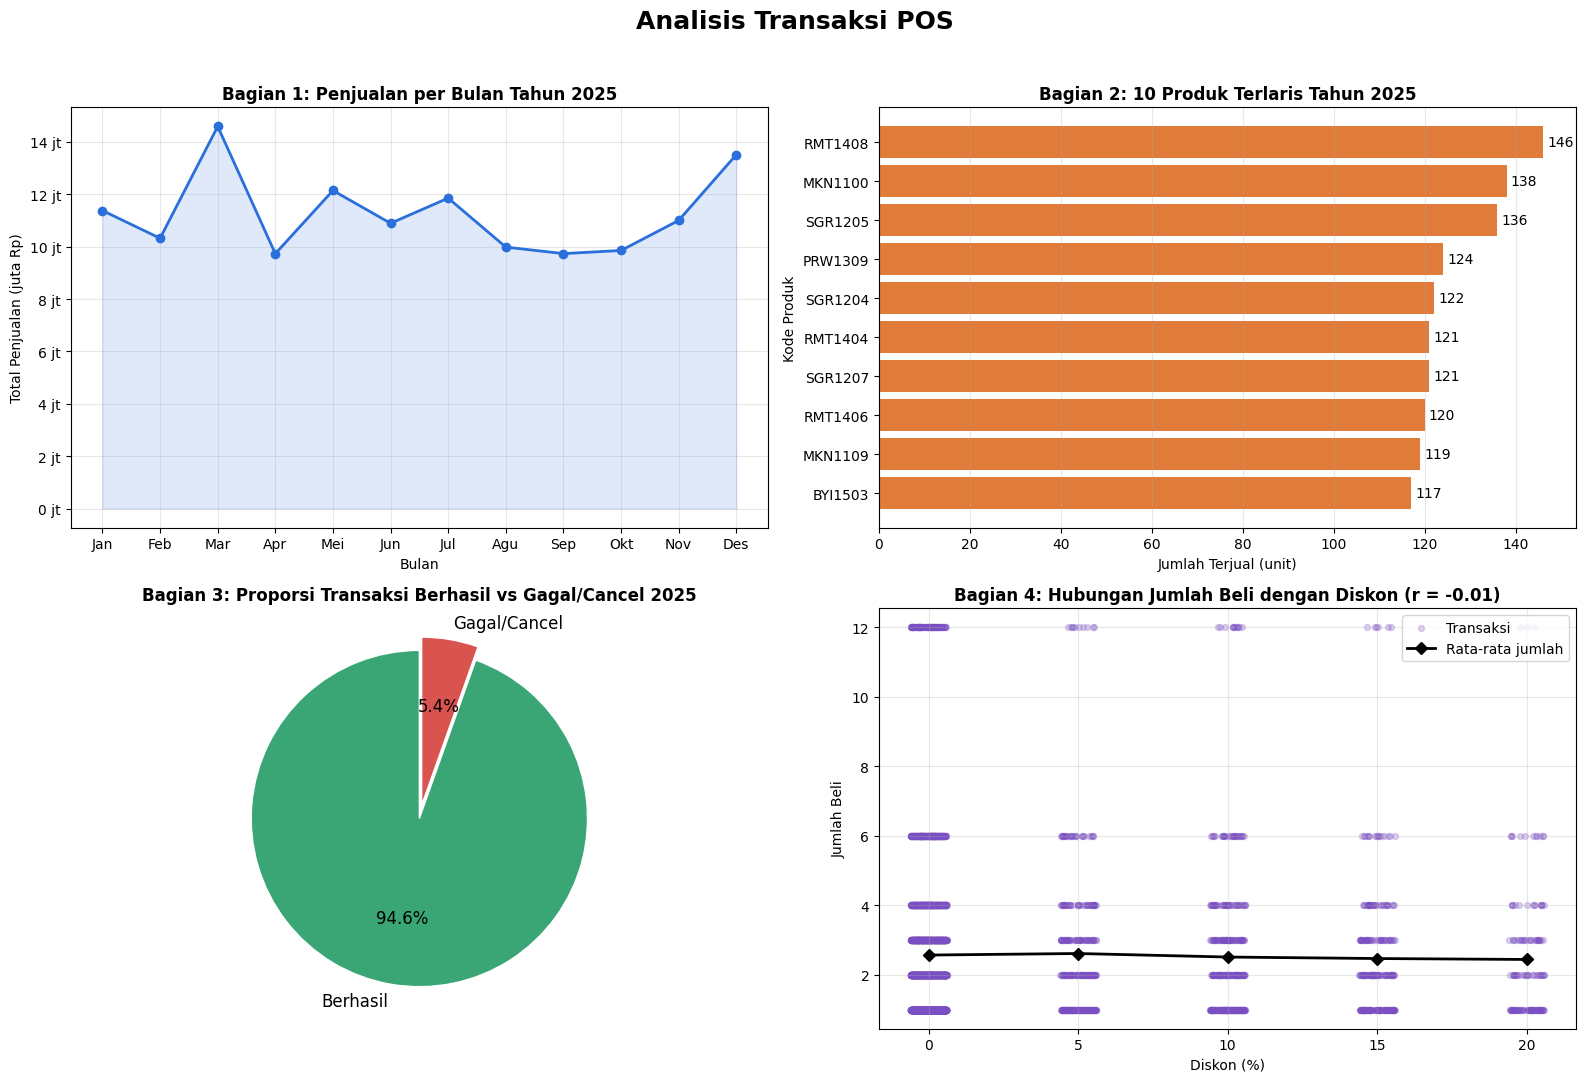

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Analisis Transaksi POS", fontsize=18, fontweight="bold")

plot_bagian1(axs[0, 0])   # A
plot_bagian2(axs[0, 1])   # B
plot_bagian3(axs[1, 0])   # C
plot_bagian4(axs[1, 1])   # D

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Cell 9 - Ringkasan

In [ ]:
print(f"Total penjualan 2025 (SELESAI): Rp {jual_bulan.sum():,.0f}")
print(f"Bulan tertinggi : {nama_bulan[jual_bulan.values.argmax()]}")
print(f"Produk terlaris : {top10.index[-1]} ({int(top10.iloc[-1])} unit)")
print(f"Transaksi berhasil: {prop['Berhasil']} | gagal/cancel: {prop['Gagal/Cancel']}")
print(f"Korelasi jumlah vs diskon: {korelasi:.3f}")

Total penjualan 2025 (SELESAI): Rp 135,001,100
Bulan tertinggi : Mar
Produk terlaris : RMT1408 (146 unit)
Transaksi berhasil: 2345 | gagal/cancel: 135
Korelasi jumlah vs diskon: -0.014
